<a href="https://colab.research.google.com/github/areebashahzad003/AreebaShahzad/blob/main/ML_Model_Colab_File.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os, glob, warnings, numpy as np, pandas as pd
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, silhouette_score, adjusted_rand_score
from sklearn.cluster import KMeans
from scipy.spatial.distance import pdist, squareform
from google.colab import files

# In the dialog, choose:  Downloads > FYP > ML_ready_STRICT_real_age_BMI_no_blanks.csv
files.upload()
print(glob.glob("*.csv"))

Saving ML model dataset.csv to ML model dataset.csv
['ML model dataset.csv']


In [2]:
FILE = "ML model dataset.csv"
if not os.path.exists(FILE):
    FILE = glob.glob("ML*model*dataset*.csv")[0]
print("Using:", FILE)

OUT = "FYP_ML_results"; os.makedirs(OUT, exist_ok=True)
POPS = ["USA/Canada", "Europe", "Asia"]
MIN_N, REPS = 15, 3

df = pd.read_csv(FILE)
GENERA = list(df.columns[df.columns.get_loc("regional_diet_context") + 1:])
df["Prevotella"] = df["Prevotella"] + df["Segatella"]      # same group, named differently in 16S and shotgun
GENERA = [g for g in GENERA if g != "Segatella"]
print(df.shape, "samples x columns;", len(GENERA), "genera")

d = df[df.metabolic_status.isin(["Healthy", "Disease"])]
cnt = d.groupby(["study", "metabolic_status"]).size().unstack(fill_value=0)
STUDIES = list(cnt[(cnt.Healthy >= MIN_N) & (cnt.Disease >= MIN_N)].index)
d = d[d.study.isin(STUDIES)].reset_index(drop=True)
d["pop"] = d.continent.map({"North America": "USA/Canada", "Europe": "Europe", "Asia": "Asia"})
print(d.groupby(["pop", "study", "country", "assay"]).metabolic_status.value_counts().unstack())

def clr(P, pc=1e-4):
    L = np.log(P / 100.0 + pc); return L - L.mean(1, keepdims=True)

X = pd.DataFrame(clr(d[GENERA].values), columns=GENERA)
y = (d.metabolic_status == "Disease").astype(int).values
st = d.study.values
pop_of = d.drop_duplicates("study").set_index("study")["pop"]
# age group and sex are extra inputs; BMI is NOT used because obesity is defined by BMI (it would leak the label)
COV = pd.get_dummies(d[["age_group", "sex"]].astype(str)).astype(float)

def enet():
    return make_pipeline(StandardScaler(), LogisticRegression(penalty="elasticnet", solver="saga",
                         l1_ratio=0.5, C=0.1, class_weight="balanced", max_iter=3000))

def cv_auc(M, yy, reps=REPS):
    a = []
    for r in range(reps):
        p = np.zeros(len(yy))
        for tr, te in StratifiedKFold(5, shuffle=True, random_state=r).split(M, yy):
            p[te] = enet().fit(M[tr], yy[tr]).predict_proba(M[te])[:, 1]
        a.append(roc_auc_score(yy, p))
    return float(np.mean(a))

Using: ML model dataset.csv
(3135, 399) samples x columns; 381 genera
metabolic_status                                     Disease  Healthy
pop        study              country       assay                    
Asia       PRJDB9293          Indonesia     16S           42       25
           PRJEB53017         Pakistan      16S           48       46
           PRJNA422434        China         Shotgun      182      184
Europe     PRJEB1786          Sweden        Shotgun       60       19
           PRJEB4336          Denmark       Shotgun      164       88
           PRJEB7774          Austria       Shotgun       22       21
USA/Canada AGP (American Gut) Canada        16S           22       34
                              United States 16S          325      641


In [3]:
coef, eff = {}, {}
for s in STUDIES:
    i = st == s
    coef[s] = pd.Series(enet().fit(X[i].values, y[i]).named_steps["logisticregression"].coef_[0], index=GENERA)
    A, B = X[i][y[i] == 1], X[i][y[i] == 0]
    eff[s] = ((A.mean() - B.mean()) / np.sqrt((A.var() + B.var()) / 2).replace(0, np.nan)).fillna(0)  # + = higher in disease

rows = []
for p in POPS:
    ss = [s for s in STUDIES if pop_of[s] == p]
    rows.append(pd.DataFrame({"pop": p, "genus": GENERA,
        "ml_coef": pd.concat([coef[s] for s in ss], axis=1).mean(1).values,
        "effect": pd.concat([eff[s] for s in ss], axis=1).mean(1).values,
        "prevalence": (d.loc[d["pop"] == p, GENERA] > 0).mean().values}))
R = pd.concat(rows); R.to_csv(f"{OUT}/Result1_ranking_per_population.csv", index=False)
W  = R.pivot(index="genus", columns="pop", values="ml_coef")[POPS]
E  = R.pivot(index="genus", columns="pop", values="effect")[POPS]
PV = R.pivot(index="genus", columns="pop", values="prevalence")[POPS]

# top-10 genera read from your three genus tables (Segatella counted as Prevotella)
QIIME_TOP10 = {
 "USA/Canada": ["Bacteroides","Escherichia","Faecalibacterium","Prevotella","Blautia","Agathobacter","Akkermansia","Alistipes","Vescimonas","Parabacteroides","Pseudomonas","Acinetobacter","Alcaligenes"],
 "Europe": ["Bacteroides","Phocaeicola","Faecalibacterium","Prevotella","Agathobacter","Blautia","Ruminococcoides","Alistipes","Gemmiger","Lachnospira","Bifidobacterium","Anaerostipes","Coprococcus"],
 "Asia": ["Prevotella","Phocaeicola","Bacteroides","Faecalibacterium","Lachnospira","Agathobacter","Alistipes","Bifidobacterium","Roseburia","Ruminococcoides","Romboutsia","Blautia","Escherichia","Gemmiger","Megamonas","Clostridium_sensu_stricto"]}

same_dir = (np.sign(E).nunique(axis=1) == 1) & (PV.min(axis=1) >= 0.20)
cand = same_dir & (E.abs().mean(axis=1) >= 0.15)
C = pd.DataFrame({f"effect_{p}": E[p] for p in POPS} | {f"ML_{p}": W[p] for p in POPS})[cand]
C["mean_effect"] = E.abs().mean(axis=1)[cand]
C["populations_where_ML_agrees"] = np.sign(W[POPS]).eq(np.sign(E[POPS].mean(axis=1)), axis=0).sum(axis=1)[cand]
C["direction"] = np.where(E[POPS].mean(axis=1)[cand] > 0, "HIGHER in disease", "HIGHER in healthy")
C["in_QIIME_top10_of"] = [", ".join(p for p in POPS if g in QIIME_TOP10[p]) for g in C.index]
C = C.sort_values(["populations_where_ML_agrees", "mean_effect"], ascending=False)
C.round(3).to_csv(f"{OUT}/Result1_consensus_bacteria_ML_vs_QIIME.csv")
display(C.round(2))
print("\nMarkers of HEALTH :", list(C[C.direction == "HIGHER in healthy"].index[:5]))
print("Markers of DISEASE:", list(C[C.direction == "HIGHER in disease"].index[:5]))

,effect_USA/Canada,effect_Europe,effect_Asia,ML_USA/Canada,ML_Europe,ML_Asia,mean_effect,populations_where_ML_agrees,direction,in_QIIME_top10_of
genus,,,,,,,,,,
Anaerobutyricum,0.06,0.40,0.39,0.05,0.04,0.02,0.28,3,HIGHER in disease,
Collinsella,0.26,0.10,0.19,0.15,0.01,0.04,0.18,3,HIGHER in disease,
Oliverpabstia,0.04,0.04,0.42,0.03,0.06,0.03,0.17,3,HIGHER in disease,
Faecalibacterium,-0.22,-0.10,-0.77,-0.04,0.00,-0.19,0.37,2,HIGHER in healthy,"USA/Canada, Europe, Asia"
Negativibacillus,0.13,0.34,0.42,0.01,0.05,0.00,0.30,2,HIGHER in disease,
Blautia,0.08,0.58,0.09,-0.02,0.02,0.00,0.25,2,HIGHER in disease,"USA/Canada, Europe, Asia"
Streptococcus,0.26,0.31,0.15,0.16,0.00,-0.00,0.24,2,HIGHER in disease,
Lachnospira,-0.27,-0.22,-0.15,-0.04,-0.01,0.00,0.22,2,HIGHER in healthy,"Europe, Asia"
Adlercreutzia,0.03,0.18,0.39,0.01,0.01,0.00,0.20,2,HIGHER in disease,



Markers of HEALTH : ['Faecalibacterium', 'Lachnospira', 'Coprococcus', 'Intestinibacter']
Markers of DISEASE: ['Anaerobutyricum', 'Collinsella', 'Oliverpabstia', 'Negativibacillus', 'Blautia']


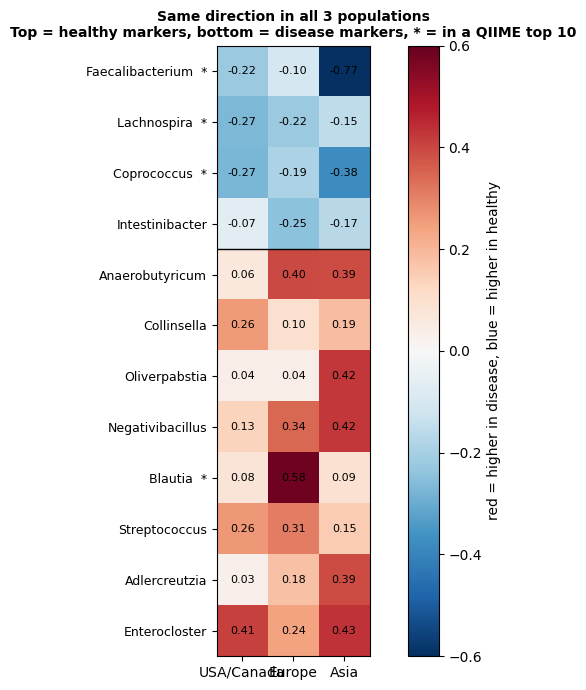

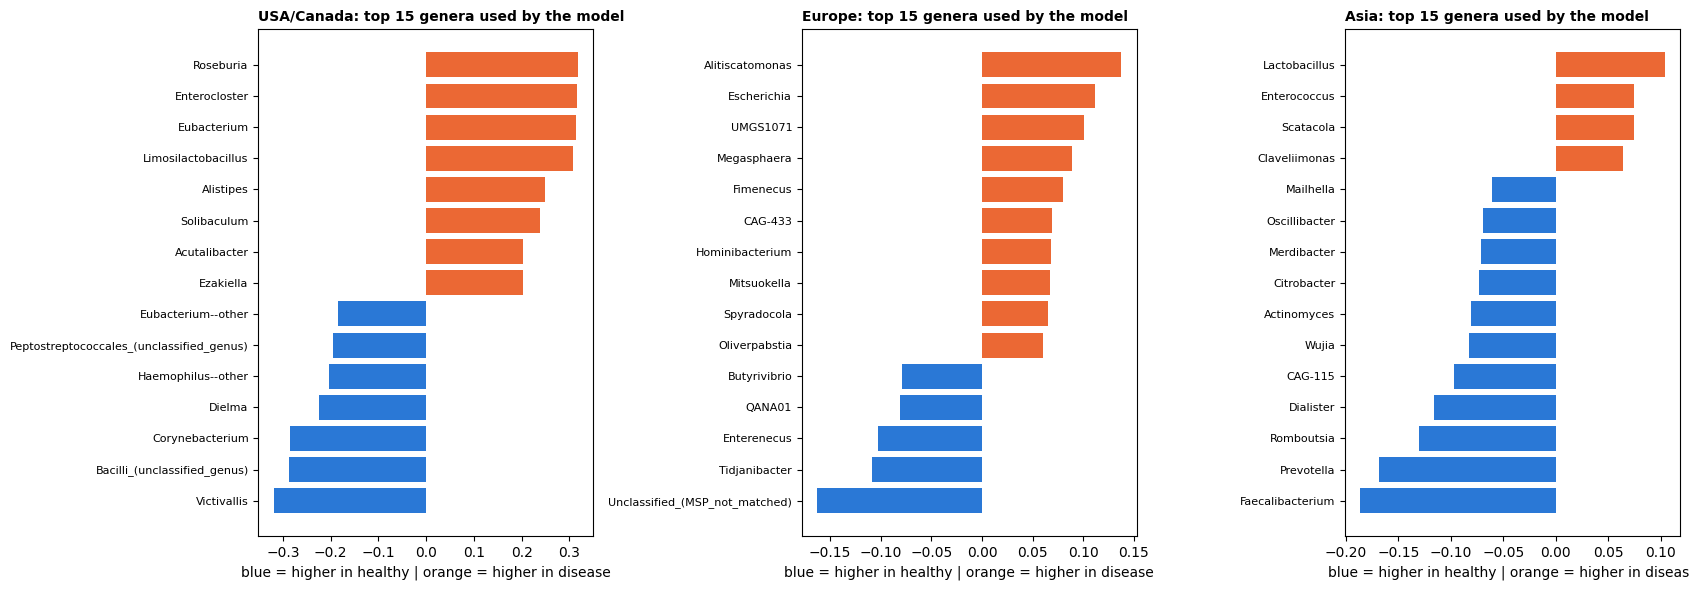

In [4]:
top = pd.concat([C[C.direction == "HIGHER in healthy"].head(8), C[C.direction == "HIGHER in disease"].head(8)])
nh = int((top.direction == "HIGHER in healthy").sum())
fig, a = plt.subplots(figsize=(8, 7)); M_ = top[[f"effect_{p}" for p in POPS]].values
im = a.imshow(M_, cmap="RdBu_r", vmin=-.6, vmax=.6); a.set_xticks(range(3)); a.set_xticklabels(POPS)
a.set_yticks(range(len(top))); a.set_yticklabels([g + ("  *" if top.in_QIIME_top10_of[g] else "") for g in top.index], fontsize=9)
for i in range(M_.shape[0]):
    for j in range(3): a.text(j, i, f"{M_[i, j]:.2f}", ha="center", va="center", fontsize=8)
a.axhline(nh - .5, color="k", lw=1); fig.colorbar(im, label="red = higher in disease, blue = higher in healthy")
a.set_title("Same direction in all 3 populations\nTop = healthy markers, bottom = disease markers, * = in a QIIME top 10", fontsize=10, fontweight="bold")
fig.tight_layout(); fig.savefig(f"{OUT}/Fig1_consensus_bacteria.png", dpi=200, bbox_inches="tight"); plt.show()

fig, axs = plt.subplots(1, 3, figsize=(17, 6))
for a, p in zip(axs, POPS):
    t = R[R["pop"] == p]; t = t.reindex(t.ml_coef.abs().sort_values(ascending=False).index).head(15).sort_values("ml_coef")
    a.barh(t.genus, t.ml_coef, color=np.where(t.ml_coef > 0, "#eb6834", "#2a78d6"))
    a.set_title(f"{p}: top 15 genera used by the model", loc="left", fontsize=10, fontweight="bold")
    a.set_xlabel("blue = higher in healthy | orange = higher in disease"); a.tick_params(axis="y", labelsize=8)
fig.tight_layout(); fig.savefig(f"{OUT}/Fig2_top_genera_per_population.png", dpi=200); plt.show()

,population,country,study,n,n_disease,AUC_all_genera,AUC_common_6,AUC_wider_14,AUC_6_random_genera,AUC_age_sex_only,AUC_all_genera_plus_age_sex
0,USA/Canada,United States,AGP (American Gut),1022,347,0.724,0.562,0.628,0.583,0.527,0.727
1,Asia,Indonesia,PRJDB9293,67,42,0.571,0.556,0.565,0.503,0.537,0.549
2,Europe,Sweden,PRJEB1786,79,60,0.664,0.708,0.696,0.660,0.504,0.665
3,Europe,Denmark,PRJEB4336,252,164,0.691,0.539,0.559,0.532,0.458,0.689
4,Asia,Pakistan,PRJEB53017,94,48,0.866,0.867,0.867,0.678,0.499,0.869
5,Europe,Austria,PRJEB7774,43,22,0.750,0.634,0.719,0.476,0.472,0.746
6,Asia,China,PRJNA422434,366,182,0.693,0.617,0.637,0.557,0.717,0.743


AUC_all_genera                 0.708
AUC_common_6                   0.640
AUC_wider_14                   0.667
AUC_6_random_genera            0.570
AUC_age_sex_only               0.531
AUC_all_genera_plus_age_sex    0.713
dtype: float64


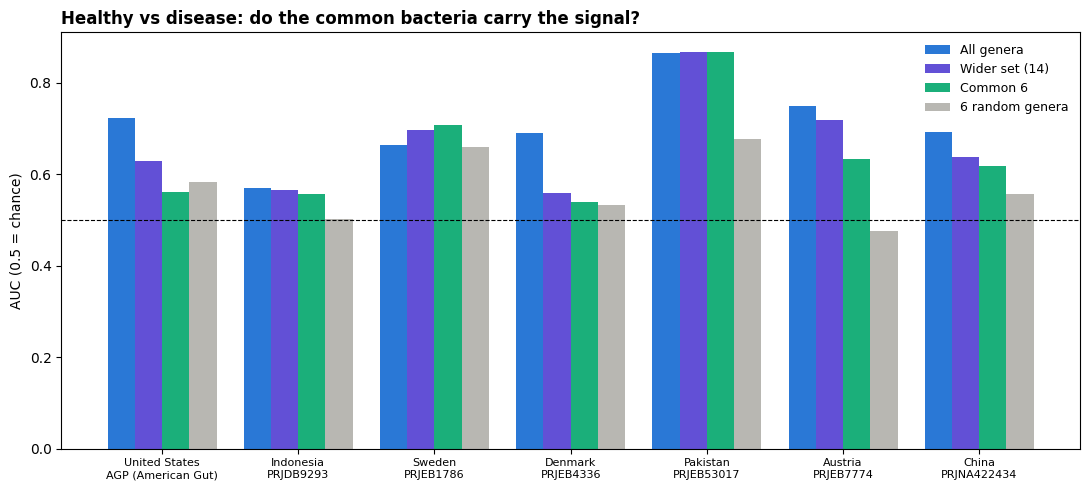

In [5]:
CORE = ["Agathobacter", "Alistipes", "Bacteroides", "Blautia", "Faecalibacterium", "Prevotella"]
WIDE = CORE + ["Phocaeicola", "Lachnospira", "Ruminococcoides", "Escherichia", "Gemmiger", "Bifidobacterium", "Akkermansia", "Roseburia"]
rng = np.random.default_rng(0); rows = []
for s in STUDIES:
    i = st == s; yy = y[i]; Xi = X[i]; Ci = COV[i]; Ci = Ci.loc[:, Ci.std() > 0]
    rows.append(dict(population=pop_of[s], country=d.country[i].iloc[0], study=s, n=int(i.sum()), n_disease=int(yy.sum()),
        AUC_all_genera=cv_auc(Xi.values, yy), AUC_common_6=cv_auc(Xi[CORE].values, yy), AUC_wider_14=cv_auc(Xi[WIDE].values, yy),
        AUC_6_random_genera=np.mean([cv_auc(Xi[list(rng.choice(GENERA, 6, replace=False))].values, yy, 1) for _ in range(10)]),
        AUC_age_sex_only=cv_auc(Ci.values, yy) if Ci.shape[1] else np.nan,
        AUC_all_genera_plus_age_sex=cv_auc(np.hstack([Xi.values, Ci.values]), yy)))
T = pd.DataFrame(rows).round(3); T.to_csv(f"{OUT}/Result2_common_set_vs_all.csv", index=False)
display(T); print(T.iloc[:, 5:].mean().round(3))

fig, a = plt.subplots(figsize=(11, 5)); x = np.arange(len(T)); w = .2
for k, (c, col, lab) in enumerate([("AUC_all_genera", "#2a78d6", "All genera"), ("AUC_wider_14", "#6250d6", "Wider set (14)"),
                                   ("AUC_common_6", "#1baf7a", "Common 6"), ("AUC_6_random_genera", "#b8b7b2", "6 random genera")]):
    a.bar(x + (k - 1.5) * w, T[c], w, color=col, label=lab)
a.axhline(.5, color="k", lw=.8, ls="--"); a.set_xticks(x); a.set_xticklabels(T.country + "\n" + T.study, fontsize=8)
a.set_ylabel("AUC (0.5 = chance)"); a.legend(frameon=False, fontsize=9)
a.set_title("Healthy vs disease: do the common bacteria carry the signal?", loc="left", fontweight="bold")
fig.tight_layout(); fig.savefig(f"{OUT}/Fig3_common_set_vs_all.png", dpi=200); plt.show()

All genera (rows = trained on, columns = tested on):


,USA/Canada,Europe,Asia
USA/Canada,NaN,0.539,0.50
Europe,0.488,NaN,0.57
Asia,0.561,0.591,NaN


Common 6:


,USA/Canada,Europe,Asia
USA/Canada,NaN,0.589,0.639
Europe,0.509,NaN,0.483
Asia,0.549,0.478,NaN


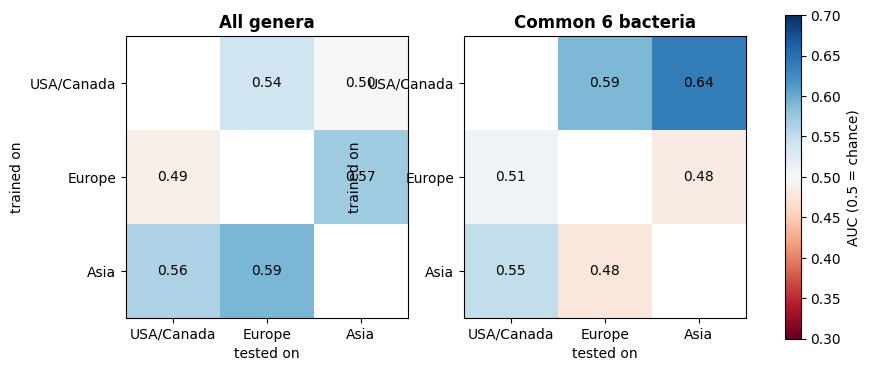

In [6]:
def zs(M, sv):
    o = M.astype(float).copy()
    for s in np.unique(sv):
        m = sv == s; o[m] = (M[m] - M[m].mean(0)) / (M[m].std(0) + 1e-9)
    return o

def pop_matrix(cols):
    Mx = pd.DataFrame(np.nan, index=POPS, columns=POPS)
    for A_ in POPS:
        for B_ in POPS:
            if A_ == B_: continue
            ia, ib = (d["pop"] == A_).values, (d["pop"] == B_).values
            m = LogisticRegression(C=.05, class_weight="balanced", max_iter=3000).fit(zs(X.loc[ia, cols].values, st[ia]), y[ia])
            Zb = zs(X.loc[ib, cols].values, st[ib]); sb = st[ib]; yb = y[ib]
            Mx.loc[A_, B_] = np.mean([roc_auc_score(yb[sb == s], m.predict_proba(Zb[sb == s])[:, 1]) for s in np.unique(sb)])
    return Mx

M_all, M_core = pop_matrix(GENERA), pop_matrix(CORE)
pd.concat({"all_genera": M_all, "common_6": M_core}).round(3).to_csv(f"{OUT}/Result3_population_to_population.csv")
print("All genera (rows = trained on, columns = tested on):"); display(M_all.round(3))
print("Common 6:"); display(M_core.round(3))

fig, axs = plt.subplots(1, 2, figsize=(10, 4.2))
for a, Mx, t in zip(axs, [M_all, M_core], ["All genera", "Common 6 bacteria"]):
    im = a.imshow(Mx.values.astype(float), cmap="RdBu", vmin=.3, vmax=.7)
    a.set_xticks(range(3)); a.set_xticklabels(POPS); a.set_yticks(range(3)); a.set_yticklabels(POPS)
    a.set_xlabel("tested on"); a.set_ylabel("trained on"); a.set_title(t, fontweight="bold")
    for i in range(3):
        for j in range(3):
            if i != j: a.text(j, i, f"{Mx.values[i, j]:.2f}", ha="center", va="center")
fig.colorbar(im, ax=axs, label="AUC (0.5 = chance)")
fig.savefig(f"{OUT}/Fig4_population_to_population.png", dpi=200, bbox_inches="tight"); plt.show()

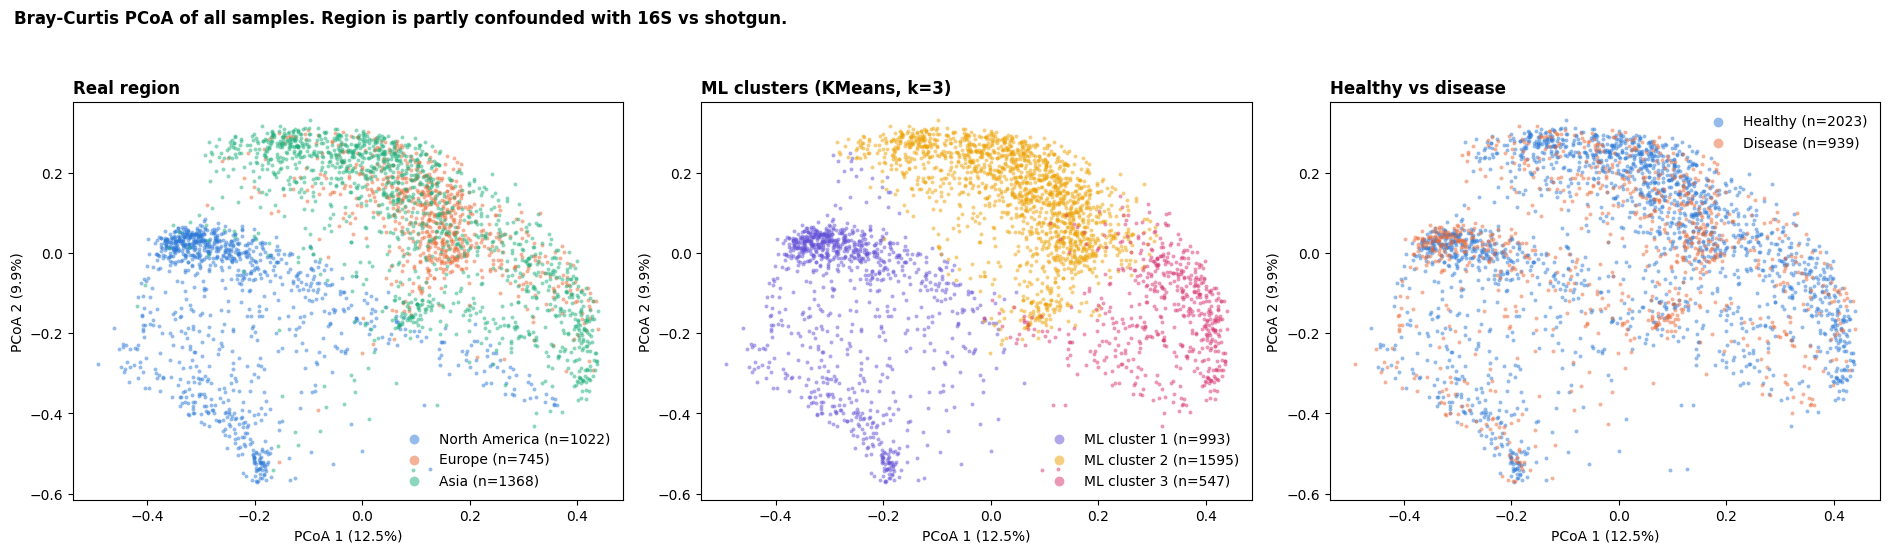

continent  Asia  Europe  North America
cluster                               
1            56       9            928
2           945     641              9
3           367      95             85


In [7]:
def pcoa(P):
    Dm = squareform(pdist(P, "braycurtis")); n = len(Dm); J = np.eye(n) - 1 / n
    w, v = np.linalg.eigh(-.5 * J @ (Dm ** 2) @ J); o = np.argsort(w)[::-1]; w, v = w[o], v[:, o]
    return v[:, :5] * np.sqrt(np.clip(w[:5], 0, None)), 100 * w[:2] / w[w > 0].sum()

Z = df[GENERA].values; Cz, evz = pcoa(Z); km = KMeans(3, n_init=20, random_state=1).fit_predict(Cz)
fig, axs = plt.subplots(1, 3, figsize=(19, 5.6)); reg = {"North America": "#2a78d6", "Europe": "#eb6834", "Asia": "#1baf7a"}
for k, c in reg.items():
    i = (df.continent == k).values; axs[0].scatter(Cz[i, 0], Cz[i, 1], s=8, alpha=.5, color=c, lw=0, label=f"{k} (n={i.sum()})")
for k, c in zip(range(3), ["#6250d6", "#eda100", "#d6336c"]):
    axs[1].scatter(Cz[km == k, 0], Cz[km == k, 1], s=8, alpha=.5, color=c, lw=0, label=f"ML cluster {k+1} (n={(km==k).sum()})")
for v_, c in [("Healthy", "#2a78d6"), ("Disease", "#eb6834")]:
    i = (df.metabolic_status == v_).values; axs[2].scatter(Cz[i, 0], Cz[i, 1], s=8, alpha=.5, color=c, lw=0, label=f"{v_} (n={i.sum()})")
for a, t in zip(axs, ["Real region", "ML clusters (KMeans, k=3)", "Healthy vs disease"]):
    a.set_title(t, loc="left", fontweight="bold"); a.set_xlabel(f"PCoA 1 ({evz[0]:.1f}%)"); a.set_ylabel(f"PCoA 2 ({evz[1]:.1f}%)"); a.legend(frameon=False, markerscale=2.5)
fig.suptitle("Bray-Curtis PCoA of all samples. Region is partly confounded with 16S vs shotgun.", x=.01, ha="left", fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, .94]); fig.savefig(f"{OUT}/Fig5_PCoA_all_regions_ML_clusters.png", dpi=200); plt.show()
print(pd.crosstab(pd.Series(km + 1, name="cluster"), df.continent))

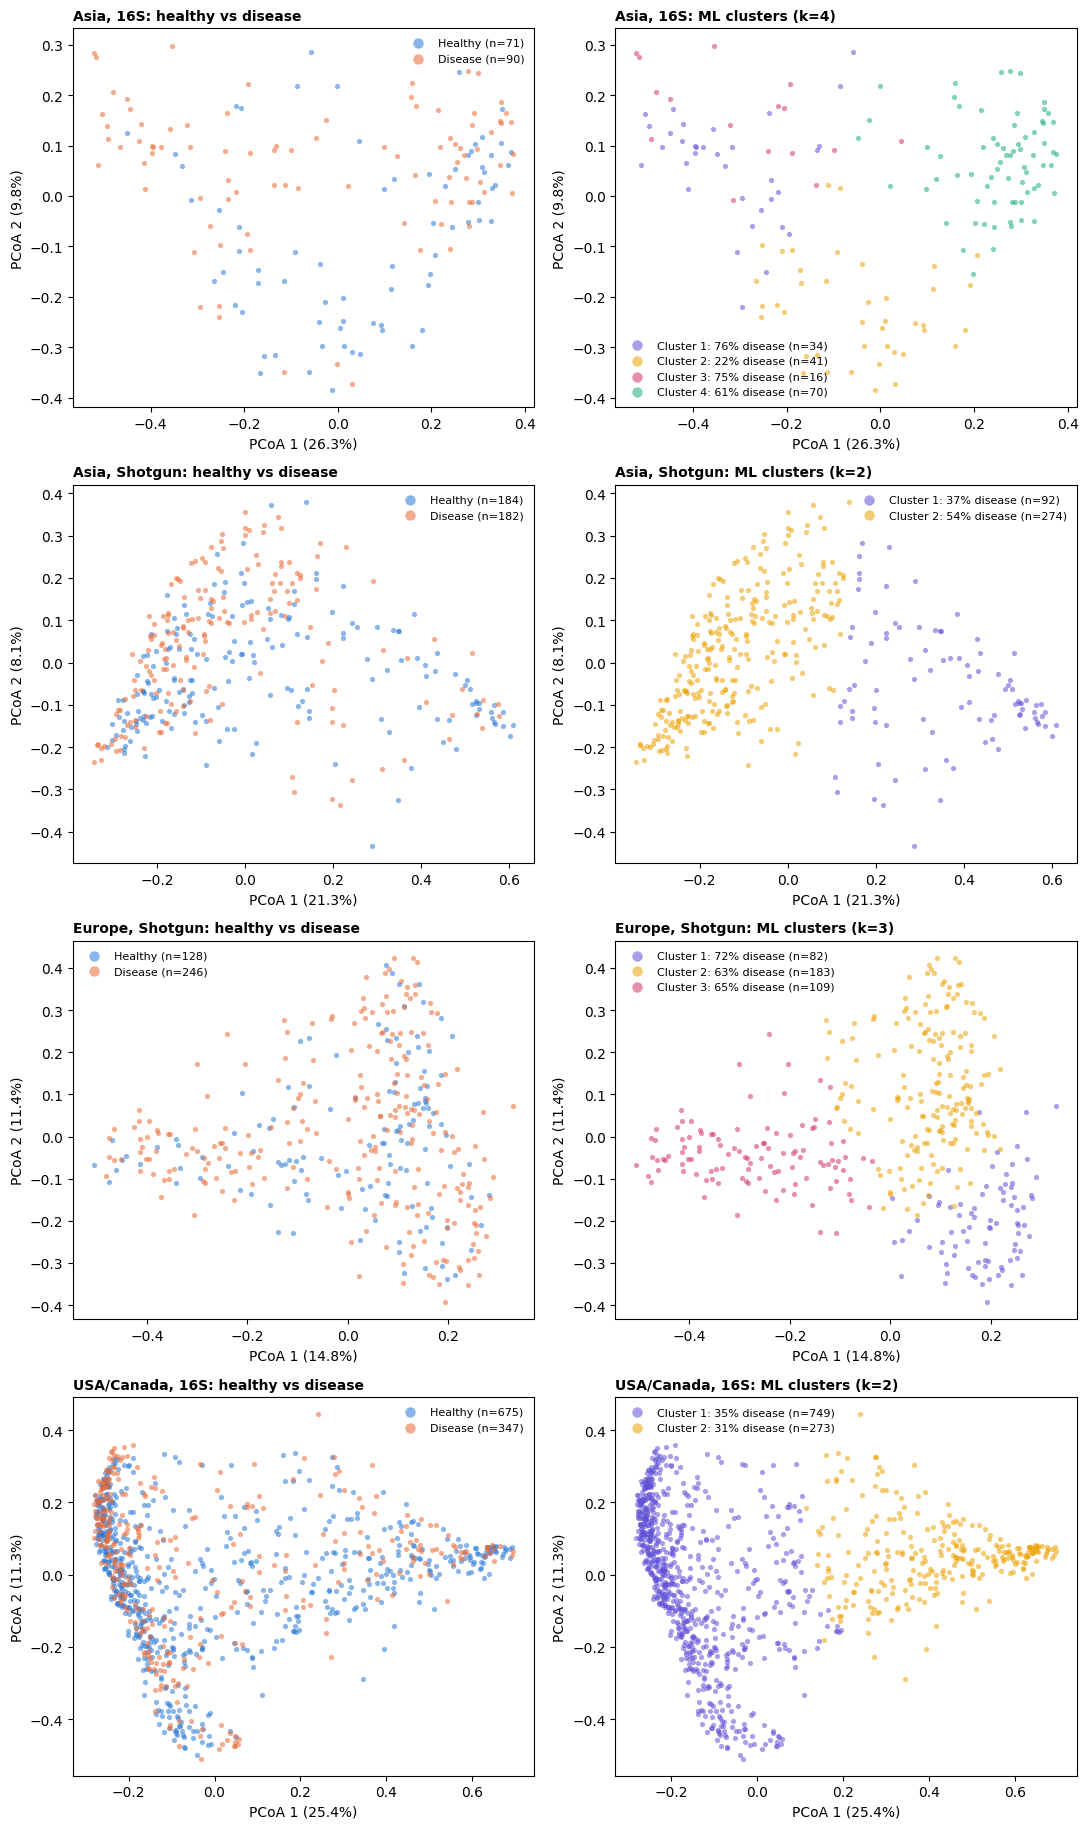

,population,assay,n,clusters,ARI_vs_disease,ARI_vs_study,ARI_vs_country
0,Asia,16S,161,4,0.074,0.498,0.498
1,Asia,Shotgun,366,2,0.014,0.000,0.000
2,Europe,Shotgun,374,3,-0.009,0.379,0.379
3,USA/Canada,16S,1022,2,-0.010,0.000,-0.027


In [8]:
groups = d.groupby(["pop", "assay"]).size().reset_index()[["pop", "assay"]].values.tolist()
fig, axs = plt.subplots(len(groups), 2, figsize=(11, 4.6 * len(groups))); res = []
for r_, (p, assay) in enumerate(groups):
    i = ((d["pop"] == p) & (d.assay == assay)).values; Cc, ev = pcoa(d.loc[i, GENERA].values); yy = y[i]
    k_best = max(range(2, 5), key=lambda k: silhouette_score(Cc, KMeans(k, n_init=10, random_state=1).fit_predict(Cc)))
    kk = KMeans(k_best, n_init=20, random_state=1).fit_predict(Cc); a0, a1 = axs[r_]
    for v_, c, nm in [(0, "#2a78d6", "Healthy"), (1, "#eb6834", "Disease")]:
        a0.scatter(Cc[yy == v_, 0], Cc[yy == v_, 1], s=14, alpha=.55, color=c, lw=0, label=f"{nm} (n={(yy==v_).sum()})")
    pal = ["#6250d6", "#eda100", "#d6336c", "#1baf7a"]
    for k in range(k_best):
        a1.scatter(Cc[kk == k, 0], Cc[kk == k, 1], s=14, alpha=.55, color=pal[k], lw=0,
                   label=f"Cluster {k+1}: {100*yy[kk==k].mean():.0f}% disease (n={(kk==k).sum()})")
    for a_, t_ in [(a0, "healthy vs disease"), (a1, f"ML clusters (k={k_best})")]:
        a_.set_title(f"{p}, {assay}: {t_}", loc="left", fontsize=10, fontweight="bold")
        a_.set_xlabel(f"PCoA 1 ({ev[0]:.1f}%)"); a_.set_ylabel(f"PCoA 2 ({ev[1]:.1f}%)"); a_.legend(frameon=False, fontsize=8, markerscale=2)
    res.append(dict(population=p, assay=assay, n=int(i.sum()), clusters=k_best, ARI_vs_disease=round(adjusted_rand_score(yy, kk), 3),
                    ARI_vs_study=round(adjusted_rand_score(st[i], kk), 3), ARI_vs_country=round(adjusted_rand_score(d.country[i], kk), 3)))
fig.tight_layout(); fig.savefig(f"{OUT}/Fig6_PCoA_per_population.png", dpi=170); plt.show()
pd.DataFrame(res).to_csv(f"{OUT}/Result4_clusters_summary.csv", index=False); display(pd.DataFrame(res))